> ## 🎤 강사 스크립트 · 이 강사용 노트북 사용법
>
> 이 노트북은 **학생용 `D17_Kokoro_실습.ipynb`의 모든 셀을 그대로 담고**, 사이사이에 **인용 블록(왼쪽 세로줄)으로 된 🎤 강사 스크립트 셀**을 끼워 넣은 것입니다. 수업 화면에는 학생용을, 강사 화면에는 이 노트북을 띄우세요.
>
> | 표시 | 뜻 |
> |---|---|
> | 🎯 | 이 블록에서 학생이 가져가야 할 한 가지 |
> | 🗣️ | 그대로 읽어도 되는 강사 멘트 |
> | 🍎 | 일상 비유 |
> | 🖥️ | 화면 시연 |
> | ❓ | 학생에게 던지는 질문 → 예상 답 |
> | 🆘 | 빈칸에서 막힌 학생에게 단계별로 주는 힌트 |
> | ⚠️ | 자주 막히는 지점 · 오개념 · 오류 |
> | 🎧 | 반 전체가 같이 들을 소리 (스피커) |
> | ➡️ | 다음 블록으로 넘어가는 연결 멘트 |
>
> **오늘의 수업 방향**: D16에서 부품으로 뜯어 본 TTS를, **실제로 쓰는 작은 모델 하나**에서 다시 찾습니다. 핵심 메시지는 **"작은 모델 + 음소 입력 + 스타일 벡터 = CPU에서도 실시간 · 여러 목소리"**, 그리고 **"한국어는 데이터와 G2P가 없으면 안 된다"** 입니다. 칠판에 쓰는 식은 **소리 샘플 = pred_dur 합 × 600**, **ref_s = pack[len(음소) − 1]** 두 개입니다.
>
> > 🍎 **하루를 꿰는 비유: 밀키트 요리사.** 요리사(KModel)는 손질된 재료(음소)만 받고, 양념 세트(voice pack)로 맛을 바꾼다. 재료 손질은 언어마다 다른 보조(misaki). 한국 재료는 손질법도, 요리 경험도 없다.
>
> > 💡 정답 · 예상 출력 · 힌트는 이 노트북에만 있습니다. **학생에게 배포하지 마세요.**

> ## 🎤 강사 스크립트 · 하루 시간표와 수업 전 점검
>
> #### 하루 시간표 (50분 수업 + 10분 휴식 × 4)
>
> | 시간 | 교시 | 노트북 | 빈칸 | 애니메이션 | 슬라이드 |
> |---|---|---|---|---|---|
> | 0:00–0:50 | 1교시 | 도입, Part 0 설치(5분+), Part 1 구조, Part 2 첫 합성 · misaki | 1 · 2 | D17-1 ~ D17-3 | p.1 ~ 7 |
> | 1:00–1:50 | 2교시 | Part 3 음소 → 길이 → 소리, 자막 타임스탬프, speed | 3 · 4 | D17-4 | p.8 ~ 10 |
> | 2:00–2:50 | 3교시 | Part 4 voice pack · 섞기 · 바꿔 끼우기 | 5 · 6 | D17-5 | p.11 ~ 14 |
> | 3:00–3:50 | 4교시 | Part 5 CPU 실시간 · 스트리밍, Part 6 한국어 실험, Part 7 정리 | 7 · 8 · 9 | D17-6 ~ D17-9 | p.15 ~ 20 |
>
> **진도가 밀릴 때 줄이는 순서** (빈칸 실습은 줄이지 않습니다)
> 1. Part 4의 '바꿔 끼우기' 셀 → 강사 화면에서만 🎧
> 2. Part 5의 스레드 비교 → 강사 결과 공유
> 3. Part 6 ASR 역검증 → `KO_SENTS[:3]`
>
> #### 수업 전 점검 (전날)
> - [ ] **CPU 런타임**과 **T4 런타임** 둘 다에서 끝까지 한 번 실행하고 Part 5 속도 표 · Part 6 CER 표를 캡처하세요. (CPU 런타임은 Part 6 Whisper가 느리므로 whisper-tiny로 바뀝니다.)
> - [ ] 설치 확인: `kokoro 0.9.4`는 **Python 3.10 ~ 3.12**에서만 설치됩니다. `misaki[en]`는 spaCy를 쓰고, 처음 G2P를 만들 때 `en_core_web_sm`이 없으면 **자동으로 내려받습니다**(Colab에는 보통 이미 있음). 설치에 1 ~ 2분.
> - [ ] 첫 실행 때 모델(약 330 MB)과 voice pack(목소리마다 약 0.5 MB)을 Hugging Face에서 내려받습니다. 반 전체가 동시에 받으면 느릴 수 있어 Part 0 직후 바로 Part 2 첫 셀까지 실행하게 하세요.
> - [ ] **스피커** 준비 (목소리 비교 · 한국어 실험은 반 전체가 같이 들으면 효과가 큼).
> - [ ] [animation.html](https://imguru-mooc.github.io/AI_Voice/day17/animation.html), [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day17/worksheet.html) 탭을 열어 둡니다.
> - [ ] 학생 안내문:
>
> ```
> D17 실습 노트북: (Colab 링크) → [파일] → [Drive에 사본 저장]
> CPU 런타임도 OK (T4면 Part 5에서 GPU 비교 + Part 6이 빨라짐) · 이어폰 준비
> 워크시트: https://imguru-mooc.github.io/AI_Voice/day17/worksheet.html
> ```
>
> #### 오늘 학생들이 가장 많이 막히는 곳
> | 위치 | 증상 | 대응 |
> |---|---|---|
> | Part 0 | `Requires-Python <3.13` 오류 | Colab Python이 3.13 이상으로 바뀐 경우. 강사 화면으로 진행하고 공지 |
> | Part 0 | spaCy 관련 버전 경고 | 제약 파일로 고정했으므로 대부분 무시해도 됨. 오류면 런타임 재시작 후 Part 0부터 |
> | Part 2 | `WARNING: Defaulting repo_id` | 경고일 뿐. 오늘 코드는 repo_id를 명시함 |
> | Part 2 | 첫 RTF가 1보다 큼 | voice 내려받기 · 첫 실행 준비 시간 포함. 셀을 한 번 더 실행 |
> | Part 4 | `Language mismatch` 경고 | 다른 언어 목소리를 영어 파이프라인에 넣을 때 나는 경고. 정상 |
> | Part 6 | `generate_from_tokens` 길이 오류 | 음소 510자 초과 → 문장을 짧게 |
> | Part 6 | 한국어 소리가 이상함 | **정상 (오늘의 결론)**. 외국인 억양인 이유를 토론 |

> ## 🎤 강사 스크립트 · 오늘의 비유 사전 (먼저 읽어 두기)
>
> | 개념 | 🍎 한 문장 비유 |
> |---|---|
> | KModel | 재료만 받으면 요리하는 **요리사** (언어를 모름) |
> | KPipeline | 언어별 **재료 손질 담당** + 양념 창고 |
> | misaki G2P | 영어 철자를 **발음 기호**로 손질 |
> | voice pack | 요리 양별 **양념 배합표** 510장 |
> | 음색 128 · 운율 128 | 양념의 **향**과 **간** |
> | 목소리 섞기 | 두 양념을 **반반 섞기** |
> | pred_dur | 음표마다 **박자** |
> | 프레임 600 샘플 | 박자 하나 = **25 ms** |
> | RTF | 요리 시간 ÷ 먹는 시간 |
> | TTFA | 주문 후 **첫 접시**가 나오기까지 |
> | 스트리밍 | 코스 요리: 첫 접시 먹는 동안 다음 접시 조리 |
> | 한국어 실험 | 한식 재료를 받았지만 **한식을 배운 적 없는** 요리사 |

# D17. 경량 TTS: Kokoro — 8,200만 파라미터로 CPU에서 실시간 합성  —  🎤 강사용

**음성 AI 전문가 과정 (160h) | 4주차 M4 음성 합성(TTS) & Voice Cloning | 4시간**

## 학습 목표
1. **Kokoro-82M**의 구조(StyleTTS 2 + iSTFTNet)를 D16에서 배운 부품(G2P · duration · pitch · Vocoder)과 연결해 설명한다.
2. `kokoro` 패키지를 **버전 충돌 없이 설치**하고, `KPipeline`으로 합성 · 저장 · RTF 측정을 한다.
3. G2P 라이브러리 **misaki**가 만든 **음소(IPA)** 를 읽고, `pred_dur`로 **단어별 시간(자막 타임스탬프)** 을 계산한다.
4. **voice pack**(510 × 256 스타일 벡터)의 구조를 이해하고, **목소리 섞기 · 음색과 운율 바꿔 끼우기 · 속도 조절**을 한다.
5. **CPU 실시간 합성**: RTF, 스레드 수, **문장 단위 스트리밍과 첫 소리까지 시간(TTFA)** 을 재고, 끊김 없이 재생되는 조건을 판정한다.
6. Kokoro에 **한국어가 없는 이유**를 확인하고, 음소를 직접 넣어 '외국인 억양 한국어'를 만든 뒤 D16 한국어 VITS와 **ASR 역검증**으로 비교한다.

## 오늘의 실습 흐름
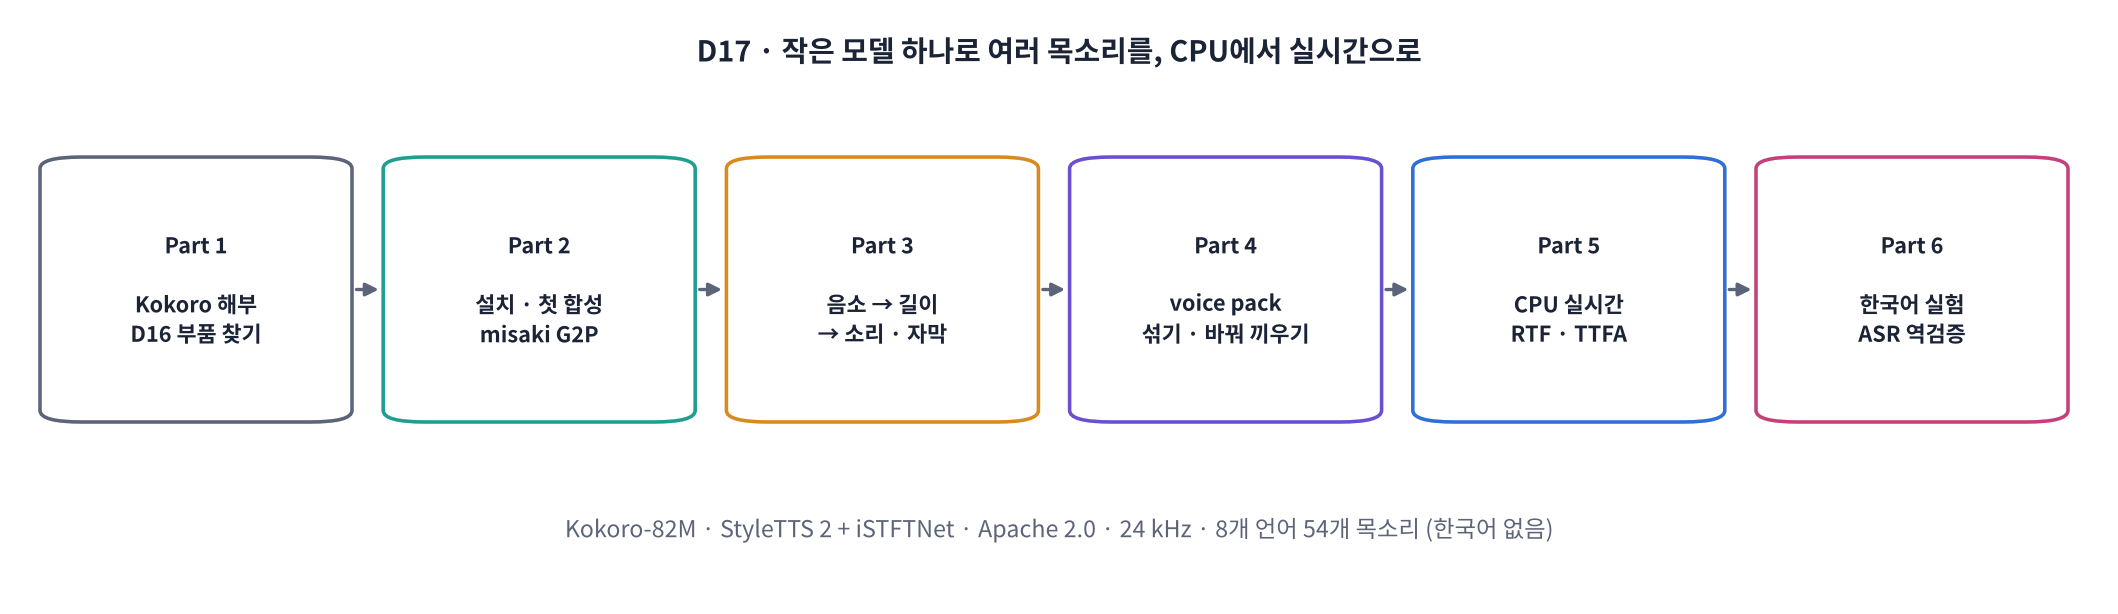

| 교시 | 내용 | 실습 |
|---|---|---|
| 1교시 | Kokoro 큰 그림, 설치, 첫 합성, misaki G2P | Part 0 ~ 2, 워크시트 1교시 |
| 2교시 | KModel 들여다보기: 음소 → 길이 → 소리, 단어 타임스탬프 | Part 3, 워크시트 2교시 |
| 3교시 | 음성 스타일: voice pack · 섞기 · 음색 / 운율 · 속도 | Part 4, 워크시트 3교시 |
| 4교시 | CPU 실시간 · 스트리밍, 한국어 실험 · ASR 역검증, 정리 | Part 5 ~ 7, 워크시트 4교시 · 노션 제출 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day17/animation.html) | 각 Part 설명을 볼 때 (Part마다 바로가기 링크가 있습니다) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day17/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다. `!`로 시작하는 줄은 리눅스 명령입니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다. 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.
- 🎧 표시가 있는 셀은 **소리를 들어 보는** 셀입니다. 이어폰을 준비하세요.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🎧 **들어 보기** | 합성 결과를 귀로 비교 |

> ⚙️ 오늘의 주인공은 **CPU**입니다. Kokoro는 일부러 **CPU에서** 돌립니다. GPU(T4)가 있으면 Part 5에서 비교하고, Part 6의 받아쓰기(Whisper)를 빠르게 합니다.
>
> 📜 **라이선스**: Kokoro-82M은 **Apache 2.0** 으로 상업 서비스에도 쓸 수 있습니다(D16의 MMS-TTS 한국어는 비상업 CC BY-NC 4.0). 단, 목소리를 다른 사람 목소리처럼 속여 쓰는 일은 라이선스와 별개로 금지입니다(D19).

> 🎬 **애니메이션 D17-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#flow) — Part 1~6 로드맵

> ## 🎤 강사 스크립트 · 도입  ⏱️ 5분
>
> 🎯 **어제 뜯어 본 부품이 '실제로 쓰는 작은 모델'에 다 들어 있다.**
>
> 🗣️ "어제 정규화, G2P, duration, Vocoder를 하나씩 봤습니다. 오늘은 8,200만 파라미터짜리 Kokoro 하나에서 그 부품을 모두 찾고, 노트북 CPU로 실시간 합성까지 해 봅니다. 마지막엔 Kokoro에 한국어를 억지로 시켜 봅니다."
>
> 🖥️ [D17-1 오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#flow). 시작 전에 Part 0 설치 셀을 먼저 돌려 두게 하세요(1 ~ 2분).

## Part 0. 준비

> 🛠️ **버전 충돌 방지 (D8 ~ D16과 같은 방식)**: Colab 기본 패키지 버전을 고정한 채 필요한 것만 설치합니다. `kokoro`는 영어 G2P(`misaki[en]`)를 위해 **spaCy**를 쓰는데, Colab에 이미 있는 spaCy · pydantic · typer 버전도 고정 목록에 넣어 바뀌지 않게 합니다. `espeak-ng`는 사전에 없는 단어와 일부 언어의 발음을 만드는 프로그램입니다.
>
> ⚠️ `kokoro 0.9.4`는 **Python 3.10 ~ 3.12**에서만 설치됩니다. Colab의 Python 버전이 바뀌었다면 설치 로그를 확인하세요.

> ## 🎤 강사 스크립트 · Part 0  ⏱️ 5분
>
> 🖥️ 설치 셀 → import 셀. `kokoro 0.9.4 · misaki 0.9.4 · spacy 3.x`, `CPU 코어 2개`(Colab 무료) 확인.
>
> ⚠️ 고정 목록에 spacy · pydantic · typer를 넣은 이유: misaki[en]가 spaCy를 쓰는데, 다른 버전이 깔리면 Colab 기본 도구들과 충돌할 수 있어서(D8부터의 원칙).

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "transformers", "tokenizers", "huggingface-hub", "datasets", "accelerate",
        "click", "numpy", "protobuf", "requests", "nltk", "regex", "spacy", "thinc", "pydantic", "typer"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))

!apt-get -qq -y install espeak-ng > /dev/null
!pip install -q -c colab_constraints.txt "kokoro>=0.9.4" "misaki[en]" soundfile librosa jiwer python-mecab-ko g2pk2 jamo uroman
print("✅ 설치 완료")

In [ ]:
import os, io, re, time, json, random, warnings
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import torch
import jiwer
import matplotlib.pyplot as plt
from IPython.display import Audio, display
import importlib.metadata as md
warnings.filterwarnings("ignore")

SR_K = 24000                                            # Kokoro 출력 샘플링 레이트
REPO = "hexgrad/Kokoro-82M"
random.seed(0); np.random.seed(0); torch.manual_seed(0)

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

GPU = torch.cuda.is_available()
N_CPU = os.cpu_count()
print(" · ".join(f"{p} {md.version(p)}" for p in ["torch", "transformers", "kokoro", "misaki", "spacy"]))
print(f"CPU 코어 {N_CPU}개 · torch 스레드 {torch.get_num_threads()}개 · GPU:", torch.cuda.get_device_name(0) if GPU else "없음")

def play(y, sr=SR_K, label=""):                         # 🎧 듣기 + 길이 표시
    y = y.numpy() if torch.is_tensor(y) else np.asarray(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    display(Audio(y.astype(np.float32), rate=sr))

## Part 1. Kokoro 큰 그림: D16의 부품들이 어디에 있나

> 💬 **쉽게 말하면**: Kokoro-82M은 **StyleTTS 2** 구조를 가볍게 줄인 모델입니다. 음소(IPA)를 받아 **길이 · 음높이(F0) · 세기**를 예측하고, **iSTFTNet** 디코더가 바로 파형을 만듭니다. 목소리는 모델 안에 있지 않고 **voice pack(스타일 벡터)** 으로 따로 넣습니다. 그래서 8,200만 파라미터로도 54개 목소리를 냅니다.

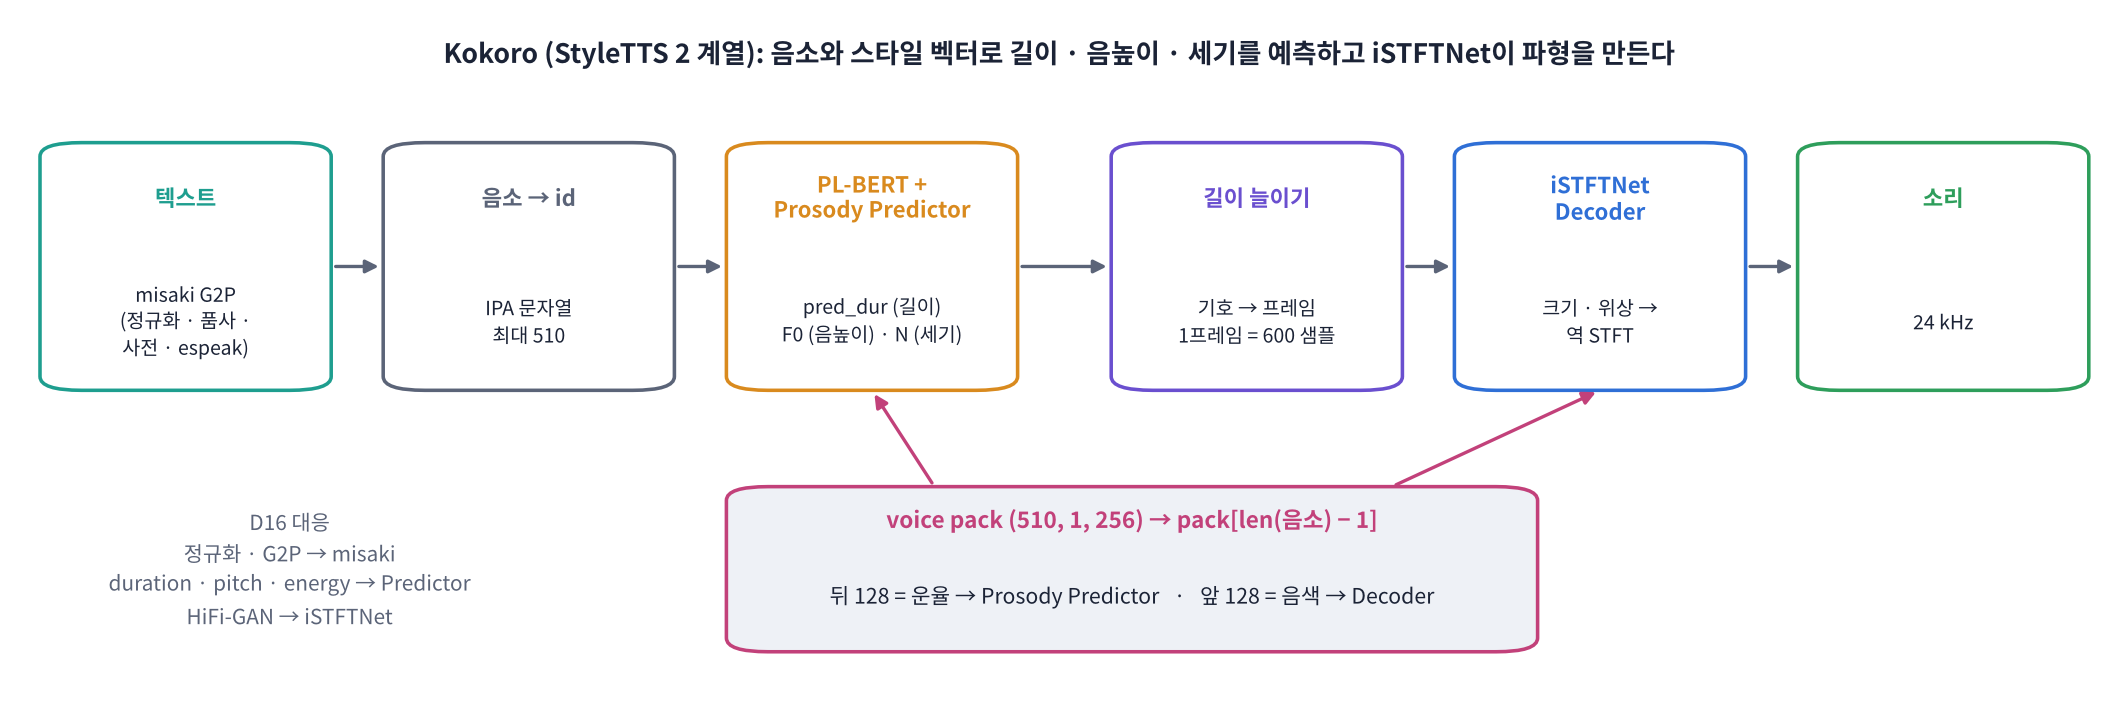

| D16에서 배운 것 | Kokoro 안의 부품 | 오늘 볼 곳 |
|---|---|---|
| 정규화 + G2P | **misaki** (spaCy 품사 + 발음 사전 + espeak-ng) | Part 2 |
| 텍스트 인코더 | PL-BERT(ALBERT) + Text Encoder | Part 3 (음소 → id) |
| Duration (FastSpeech 2) | Prosody Predictor → `pred_dur` | Part 3 (타임스탬프) |
| Pitch · Energy (FastSpeech 2 ❓) | Prosody Predictor → F0 · N | Part 4 (운율 스타일) |
| Vocoder (HiFi-GAN) | **iSTFTNet**: 크기 · 위상을 예측해 역 STFT | Part 3 |
| 화자 · 스타일 | **voice pack** 256차원 = 음색 128 + 운율 128 | Part 4 |

| | D16 MMS-TTS (VITS) | **Kokoro-82M** |
|---|---|---|
| 파라미터 | 약 3,600만 | 약 8,200만 |
| 입력 | 로마자(uroman) | **음소(IPA)** |
| 언어 · 목소리 | 1,100여 언어 · 언어마다 1개 | 8개 언어 · **54개 목소리** (한국어 없음) |
| 샘플링 | 16 kHz | **24 kHz** |
| 라이선스 | CC BY-NC 4.0 | **Apache 2.0** |
| 학습 데이터 | 언어별 성경 낭독 | 수백 시간 (허용된 데이터) · A100 약 1,000시간 |

> 🍎 **비유: 밀키트 요리사.** 요리사(KModel)는 재료(음소)만 받으면 어떤 요리든 만들고, **양념 세트(voice pack)** 를 바꾸면 맛(목소리)이 바뀝니다. 재료 손질(G2P)은 언어마다 다른 보조 요리사(misaki)가 합니다.

> 🎬 **애니메이션 D17-2:** [Kokoro 해부](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#arch) — 부품을 눌러 입력 · 출력과 D16 대응 보기

> ## 🎤 강사 스크립트 · Part 1 Kokoro 해부  ⏱️ 10분
>
> 🎯 **D16 부품 대응표를 학생이 직접 채우게 한다.**
>
> 🖥️ [D17-2 Kokoro 해부](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#arch)에서 부품마다 클릭. 칠판에 D16 부품을 쓰고 Kokoro 이름을 학생이 맞히게.
>
> ❓ "VITS(어제)는 3,600만인데 목소리 하나, Kokoro는 8,200만인데 목소리 54개. 어떻게?" → 목소리를 모델 밖 **voice pack(256개 숫자)** 으로 뺐기 때문.

## Part 2. 첫 합성과 misaki G2P

`KPipeline`은 두 가지를 맡습니다: ① 언어에 맞는 **G2P와 문장 나누기** ② **voice pack 내려받기 · 보관**. 실제 소리를 만드는 `KModel`은 **언어를 모릅니다**(음소만 받음). 그래서 모델은 하나만 만들고, 언어마다 파이프라인을 따로 둡니다.

| lang_code | 언어 | 목소리 예 (등급) | G2P |
|---|---|---|---|
| `a` | 미국 영어 | af_heart (A), af_bella (A−), am_michael (C+) | misaki (spaCy + 사전) |
| `b` | 영국 영어 | bf_emma (B−), bm_george (C) | misaki |
| `j` | 일본어 | jf_alpha (C+), jm_kumo (C−) | misaki[ja] |
| `z` | 중국어 | zf_xiaoxiao (D) | misaki[zh] |
| `e` `f` `h` `i` `p` | 스페인 · 프랑스 · 힌디 · 이탈리아 · 브라질 포르투갈어 | ff_siwis (B−) 등 | espeak-ng |

> 목소리 이름 규칙: **첫 글자 = 언어**(a · b · j …), **둘째 글자 = f(여성) · m(남성)**. 등급은 공식 VOICES.md의 '학습 데이터 양 · 품질' 추정치입니다.

> 🎬 **애니메이션 D17-3:** [misaki 음소 읽기](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#phonemes) — 문장마다 음소와 강세 · 이중모음 기호 보기

> ## 🎤 강사 스크립트 · Part 2 첫 합성  ⏱️ 5분
>
> 🗣️ "파이프라인은 언어 담당, 모델은 언어를 모르는 요리사입니다. 그래서 모델은 하나만 만들고 공유합니다."
>
> 🖥️ [D17-3 misaki 음소 읽기](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#phonemes)로 강세 기호와 A · I · O · W · Y 약속 기호 설명.

### 🧩 빈칸 실습 1 · 2: 파이프라인 만들고 RTF 재기
- 빈칸 1: 미국 영어 파이프라인의 `lang_code` (한 글자 문자열)
- 빈칸 2: RTF = 생성 시간 ÷ 소리 길이(초). 소리 길이 = 샘플 수 ÷ **샘플링 레이트 변수**

In [ ]:
# 🧩 빈칸 실습 1 · 2
from kokoro import KModel, KPipeline

kmodel = KModel(repo_id=REPO).to("cpu").eval()           # 오늘은 일부러 CPU에서
pipe = KPipeline(lang_code=____, repo_id=REPO, model=kmodel)                              # 빈칸 1
print(f"KModel 파라미터 {sum(p.numel() for p in kmodel.parameters()) / 1e6:.1f}M · 음소 기호 {len(kmodel.vocab)}개 · 최대 길이 {kmodel.context_length}")

text = "Kokoro is a small text to speech model. It runs in real time, even on a laptop CPU."
t0 = time.time()
results = list(pipe(text, voice="af_heart", speed=1.0))
gen_time = time.time() - t0
audio = torch.cat([r.audio for r in results])
RTF = gen_time / (len(audio) / ____)                                                      # 빈칸 2
for r in results:
    print("글자:", r.graphemes, "\n음소:", r.phonemes)
print(f"생성 {gen_time:.2f}초 · 소리 {len(audio) / SR_K:.2f}초 · RTF {RTF:.3f} ({'실시간보다 빠름' if RTF < 1 else '실시간보다 느림'})")
sf.write("first.wav", audio.numpy(), SR_K)
play(audio, label="af_heart (CPU)")
check(pipe.lang_code == "a" and abs(RTF * len(audio) / SR_K - gen_time) < 1e-6, hint='빈칸 1 = "a", 빈칸 2 = SR_K')

> ## 🎤 강사 스크립트 · 빈칸 실습 1 · 2  ⏱️ 10분
>
> 🆘 빈칸 1: "American English의 첫 글자" → `"a"`
> 🆘 빈칸 2: "Kokoro 샘플링 레이트 변수(24000)" → `SR_K`
>
> ✅ 예상 출력: `KModel 파라미터 약 82M · 음소 기호 100여 개 · 최대 길이 512`, 글자 · 음소 두 줄(문장 2개면 1 ~ 2조각), `RTF 0.3 ~ 0.8`(Colab CPU 2코어, 두 번째 실행 기준), 🎧, `✅`.
>
> ⚠️ 첫 실행 RTF가 2 이상이면 내려받기 시간 포함 → 다시 실행.
>
> 다음 셀(조용한 파이프라인) ✅: $12.50 → twelve dollars and fifty cents, read 과거 · 미래, St. 오류.
>
> ❓ "St. 오류는 어떻게 고칠까?" → 정규화 규칙 또는 `[St.](/stɹˈit/)` 직접 지정. 모델 재학습 불필요.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
pipe = KPipeline(lang_code="a", repo_id=REPO, model=kmodel)
RTF = gen_time / (len(audio) / SR_K)
```

**해설**: Kokoro는 **24 kHz**로 소리를 냅니다(D16의 MMS-TTS는 16 kHz). 처음 실행에는 voice pack 내려받기 시간이 섞여 RTF가 크게 나올 수 있으니, 셀을 한 번 더 실행해 보세요. 파이프라인은 결과를 **문장 조각마다 하나씩(generator)** 돌려주므로 `list()`로 모은 뒤 `torch.cat`으로 이었습니다. `KModel`을 직접 만들어 넘긴 이유는 ① CPU를 명시하고 ② 여러 언어 파이프라인이 **모델 하나를 공유**하게 하기 위해서입니다(메모리 절약).

</details>

### 2-1. misaki가 만든 음소 읽기
misaki는 ① 숫자 · 약어 정규화 ② spaCy로 **품사**를 보고 ③ 발음 사전에서 찾고 ④ 사전에 없으면 espeak-ng로 만듭니다. Kokoro의 영어 음소에는 몇 가지 **약속 기호**가 있습니다.

| 기호 | 뜻 | 기호 | 뜻 |
|---|---|---|---|
| `ˈ` | 1차 강세 (다음 음절) | `ˌ` | 2차 강세 |
| `A` | eɪ (say) | `I` | aɪ (my) |
| `O` | oʊ (go) | `W` | aʊ (now) |
| `Y` | ɔɪ (boy) | `T` | 미국식 탄설음 ɾ (water의 t) |

In [ ]:
quiet = KPipeline(lang_code="a", repo_id=REPO, model=False)   # 모델 없이 G2P만 하는 '조용한' 파이프라인
cases = ["The meeting starts at 3:15 PM.", "It costs $12.50.", "I read the book yesterday. I will read it again.",
         "Dr. Smith lives on St. James St.", "Kokoro is an open-weight TTS model."]
rows = []
for s in cases:
    for r in quiet(s):
        rows.append({"글자": r.graphemes, "음소": r.phonemes,
                     "단어별": " | ".join(f"{t.text}→{t.phonemes}" for t in r.tokens if t.phonemes)[:120]})
display(pd.DataFrame(rows))

**결과 읽기**
- `$12.50` → *twelve dollars and fifty cents*: **정규화**가 G2P 안에 들어 있습니다(D16의 `normalize_ko`와 같은 일).
- `read`가 과거(ɹˈɛd)와 미래(ɹˈid)로 다르게 나옵니다. spaCy가 **품사 · 시제**를 보고 고른 것입니다(D16 g2pk2가 형태소 분석을 쓰는 이유와 같음).
- `Dr.` → doctor는 맞았지만, `St. James St.`의 두 번째 St.(Street)도 **saint**(sənt)로 읽었습니다. 규칙 기반 정규화의 한계입니다.

**❓ 생각해 보기**: TTS 서비스에서 'St.'처럼 G2P가 틀리는 단어를 고치려면 어떻게 할까요? 모델을 다시 학습해야 할까요?

<details>
<summary>답 보기</summary>

아닙니다. Kokoro는 **음소를 입력으로 받기** 때문에, ① 입력 전에 'St.'를 'Street'로 바꾸는 **정규화 규칙**을 넣거나 ② 틀린 단어의 **음소를 직접 지정**(misaki는 `[St.](/stɹˈit/)` 같은 마크다운식 발음 지정을 지원)하면 됩니다. 모델 학습 없이 고칠 수 있다는 것이 'G2P와 모델을 나눈 구조'의 큰 장점입니다. D16의 VITS(문자 입력)는 이런 직접 지정이 어렵습니다.

</details>

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day17/worksheet.html)** — StyleTTS 2 · iSTFTNet, 82M · Apache 2.0, 언어 · 목소리 이름 규칙, KPipeline과 KModel의 역할, 24 kHz, RTF, misaki 정규화 · 품사 · 강세 기호
>
> 10문항을 풀고 **채점하기**를 누르세요. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

> ## 🎤 강사 스크립트 · 1교시 워크시트  ⏱️ 5분
>
> 🖥️ [worksheet.html 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day17/worksheet.html) → 채점. 자주 틀리는 문항: **KModel은 언어를 모른다**, **voice 이름 규칙**.

## Part 3. KModel 들여다보기: 음소 → 길이 → 소리

> 💬 **쉽게 말하면**: `KModel`은 음소 문자열을 **기호 번호(id)** 로 바꾸고, 기호마다 **몇 프레임 낼지(pred_dur)** 를 예측한 뒤, 그 길이대로 늘인 특징으로 소리를 만듭니다. Kokoro의 한 프레임은 **600 샘플(24 kHz에서 25 ms)** 이라, `pred_dur`만 있으면 **각 단어가 몇 초에 시작하는지** 알 수 있습니다(자막!).

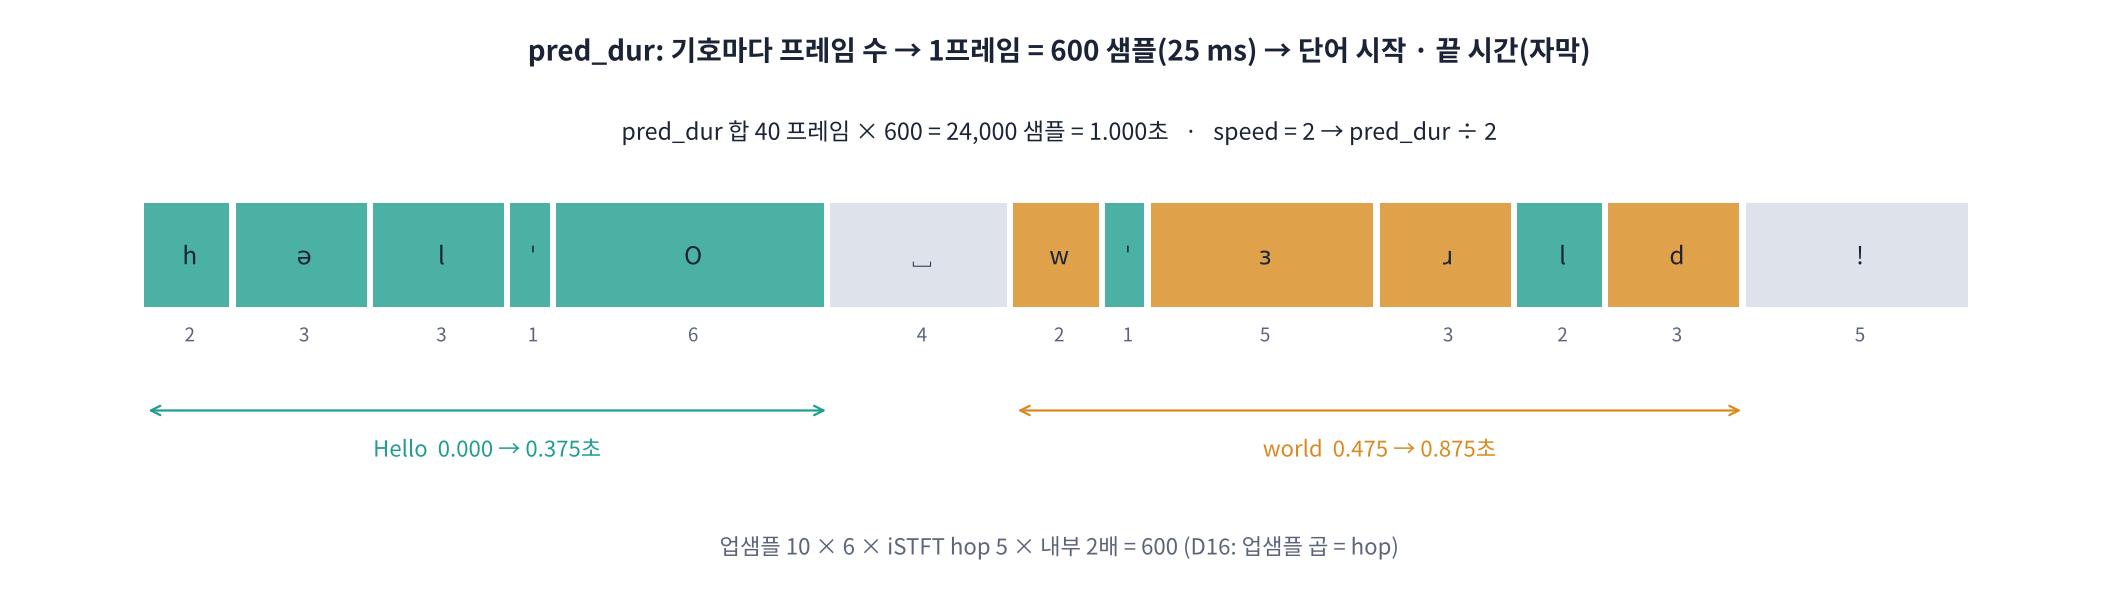

> 📐 **핵심 식 하나: 소리 길이(샘플) = pred_dur 합 × 600** — 24,000 ÷ 600 = 1초에 40프레임. speed = 2면 pred_dur가 절반이 되어 길이도 절반.

👣 **한 단계씩** (`KModel.forward_with_tokens`)
1. 음소 → id (사전에 없는 기호는 **조용히 버림**), 앞뒤에 0번(경계) 추가 → 최대 512개
2. PL-BERT가 문맥을 읽고 → Prosody Predictor가 **pred_dur = round(duration ÷ speed)**
3. 기호 특징을 pred_dur만큼 복사(D16 length regulator) → F0(음높이) · N(세기) 예측
4. iSTFTNet 디코더: 크기 · 위상 → **역 STFT** → 파형

> 🎬 **애니메이션 D17-4:** [길이와 타임스탬프](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#duration) — speed를 바꾸며 기호별 프레임과 단어 시작 시간 보기

> ## 🎤 강사 스크립트 · Part 3 길이와 자막  ⏱️ 8분
>
> 🎯 **pred_dur 합 × 600 = 소리 샘플 수. 그래서 단어 시간도 공짜로 나온다.**
>
> 🖥️ [D17-4 길이와 타임스탬프](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#duration): speed를 바꾸면 프레임과 단어 시간이 함께 줄어드는 것.
>
> 🗣️ "어제 HiFi-GAN은 업샘플 곱이 256이었죠. Kokoro는 10 × 6 × 5 × 2 = 600입니다. 24,000 ÷ 600 = 1초에 40프레임."

### 🧩 빈칸 실습 3 · 4: 프레임 → 샘플, 단어 타임스탬프
- 빈칸 3: 한 프레임이 몇 샘플인지 (24 kHz · 25 ms)
- 빈칸 4: 파이프라인은 `pred_dur`로 단어(token)마다 **시작 시간 · 끝 시간**(초) 속성을 채워 줍니다. 자막의 시작 시간 속성 이름을 넣으세요.

In [ ]:
# 🧩 빈칸 실습 3 · 4
r = next(iter(pipe("Hello world! Kokoro makes subtitles, too.", voice="af_heart")))
ids = [kmodel.vocab.get(p) for p in r.phonemes]
print("음소:", r.phonemes)
print("id  :", [i for i in ids if i is not None][:20], "…", f"(버려진 기호 {ids.count(None)}개)")
print(f"pred_dur: 기호 {len(r.pred_dur)}개 (앞뒤 경계 포함) · 합 {int(r.pred_dur.sum())} 프레임")

FRAME = ____                                                                              # 빈칸 3
print(f"소리 {len(r.audio):,} 샘플 = pred_dur 합 × {FRAME} → {int(r.pred_dur.sum()) * FRAME:,}")

def srt_time(sec):
    h, rem = divmod(sec, 3600); m, s = divmod(rem, 60)
    return f"{int(h):02d}:{int(m):02d}:{s:06.3f}".replace(".", ",")

print("\n단어 타임스탬프 (자막용)")
for t in r.tokens:
    if t.phonemes and t.start_ts is not None:
        print(f"  {srt_time(t.____)} --> {srt_time(t.end_ts)}  {t.text}")                  # 빈칸 4
play(r.audio, label="자막과 함께 들어 보기")
check(FRAME == 600 and len(r.audio) == int(r.pred_dur.sum()) * FRAME and
      all(t.start_ts <= t.end_ts for t in r.tokens if t.start_ts is not None), hint="빈칸 3 = 600, 빈칸 4 = start_ts")

> ## 🎤 강사 스크립트 · 빈칸 실습 3 · 4  ⏱️ 12분
>
> 🆘 빈칸 3: "24 kHz에서 25 ms는 몇 샘플?" → 24000 × 0.025 = `600`
> 🆘 빈칸 4: "end_ts의 짝" → `start_ts`
>
> ✅ 예상 출력: 음소 · id 목록(버려진 기호 0개), `pred_dur: 기호 N개 … 합 M 프레임`, `소리 … 샘플 = pred_dur 합 × 600 → (같은 수)`, SRT 형식 줄(00:00:00,000 --> 00:00:00,4xx Hello …), 🎧, `✅`.
>
> 🎧 다음 셀: speed 0.8 / 1.0 / 1.5. ❓ "빠르게 하면 목소리가 높아지나?" → 아니요(❓ 생각해 보기).

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
FRAME = 600
print(f"  {srt_time(t.start_ts)} --> {srt_time(t.end_ts)}  {t.text}")
```

**해설**: Kokoro 디코더는 프레임 하나를 600 샘플로 만듭니다(업샘플 10 × 6 = 60, iSTFT hop 5, 내부 2배 → 60 × 5 × 2 = 600). D16의 '업샘플 곱 = hop'과 같은 원리입니다. 파이프라인은 `join_timestamps()`에서 pred_dur를 단어별로 더해 `start_ts` · `end_ts`(초)를 채웁니다. 이 값으로 **SRT 자막**, 노래방식 글자 강조, 립싱크 아바타를 만들 수 있습니다. 별도 정렬 모델(D9 WhisperX)이 필요 없다는 것이 장점입니다. 단, 숫자는 *반 프레임* 단위의 근사라 수십 ms 오차가 있을 수 있습니다.

</details>

In [ ]:
# speed는 pred_dur을 나눌 뿐: 1.0 vs 1.5 비교
for sp in [0.8, 1.0, 1.5]:
    r2 = next(iter(pipe("Speed only changes the duration of each sound.", voice="af_heart", speed=sp)))
    print(f"speed {sp}: 프레임 {int(r2.pred_dur.sum())} · {len(r2.audio) / SR_K:.2f}초")
    play(r2.audio, label=f"speed {sp}")

**❓ 생각해 보기**: Kokoro의 F0(음높이)는 길이를 정한 **다음에** 예측합니다. speed를 1.5로 빠르게 했을 때 목소리 높이가 올라갈까요?

<details>
<summary>답 보기</summary>

올라가지 않습니다. speed는 **duration만** 나누고, F0는 그 늘이거나 줄인 프레임 위에서 따로 예측되므로 높이는 거의 그대로입니다(D16의 'mel 프레임 반복 → 음높이 그대로'와 같은 원리). 녹음을 빨리 재생하면 목소리가 '다람쥐'처럼 높아지는 것과 다릅니다. 실제로 들어 보면 빠르기만 바뀌고, 너무 빠르면 발음이 뭉개집니다(모델이 학습한 속도 범위를 벗어나기 때문).

</details>

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day17/worksheet.html)** — 음소 → id, 버려지는 기호, 512 길이 한계와 문장 나누기, pred_dur, 프레임 600 샘플 · 25 ms, speed, 타임스탬프 · SRT, F0 · N, iSTFTNet
>
> 10문항을 풀고 **채점하기**를 누르세요.

> ## 🎤 강사 스크립트 · 2교시 워크시트  ⏱️ 5분
>
> 🖥️ [worksheet.html 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day17/worksheet.html). 자주 틀리는 문항: **600 계산**, **버려지는 기호**, **speed와 음높이**.

## Part 4. 음성 스타일: voice pack 열어 보기 · 섞기 · 바꿔 끼우기

> 💬 **쉽게 말하면**: 목소리 하나(voice pack)는 `.pt` 파일 하나이고, 속은 **(510, 1, 256)** 크기의 숫자 묶음입니다. 문장의 **음소 개수**에 맞는 줄 하나(256개 숫자)를 꺼내 쓰고, 그 256개 중 **앞 128개는 음색(디코더)**, **뒤 128개는 운율(길이 · 음높이 예측기)** 에 들어갑니다. 숫자이므로 **평균을 내면 목소리가 섞입니다.**

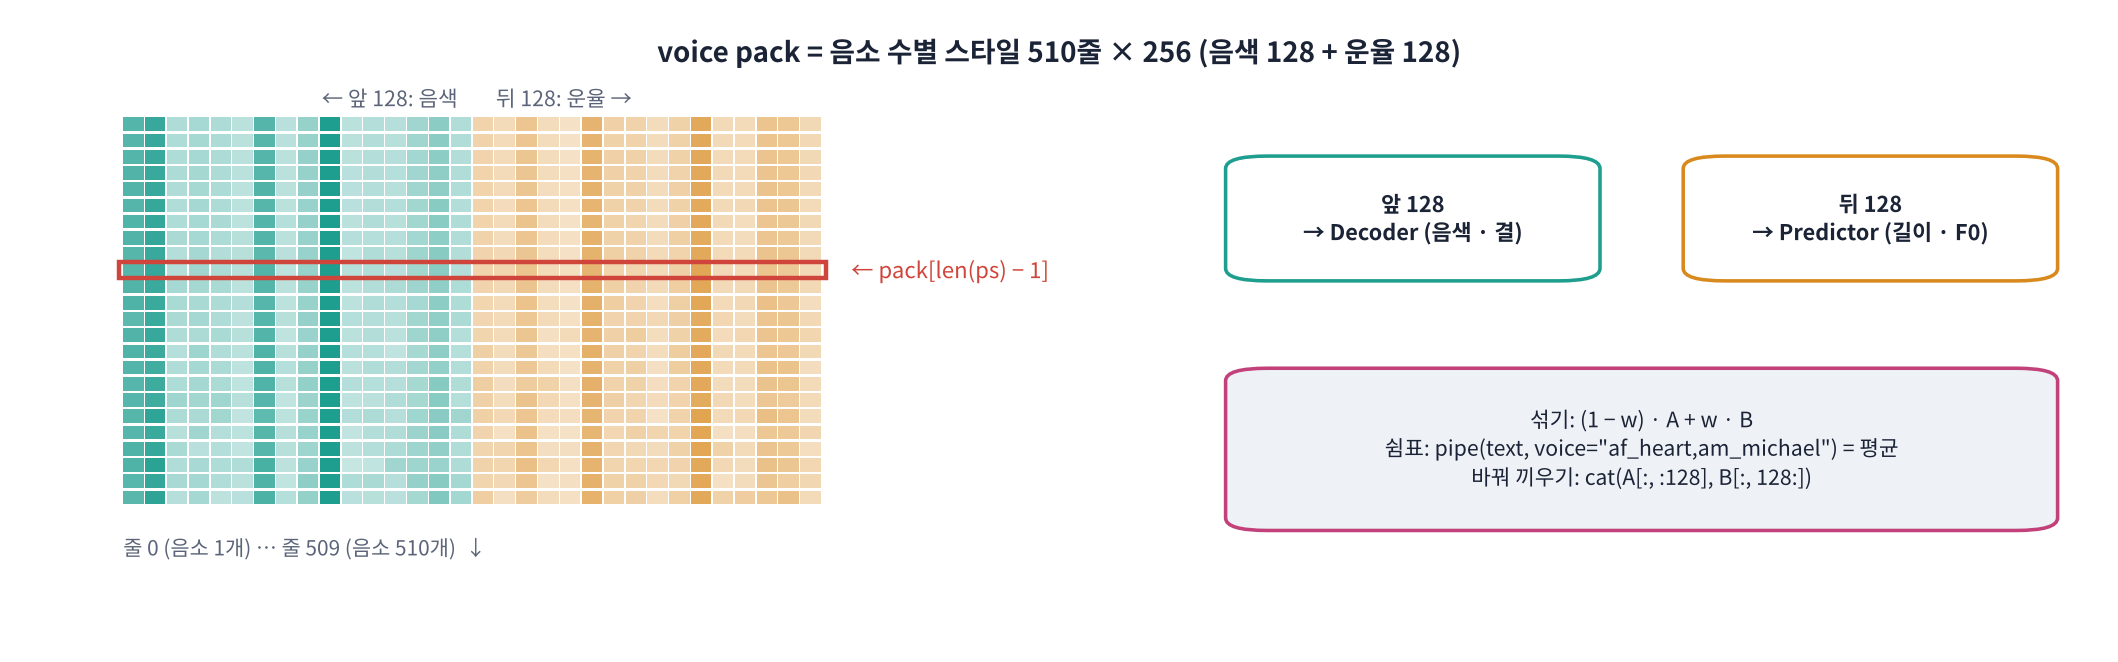

> 📐 **핵심 식 하나: ref_s = pack[len(음소) − 1]** → 앞 128 = 음색(timbre), 뒤 128 = 운율(prosody)

> 🍎 **비유: 양념 세트.** 한 상자(voice pack)에 요리 양(음소 수)별로 510가지 배합이 들어 있고, 각 배합은 '향(음색) 반 + 간(운율) 반'입니다. 두 상자를 반씩 섞으면 중간 맛이 나고, 향은 A 상자 · 간은 B 상자에서 가져올 수도 있습니다.

> 🎬 **애니메이션 D17-5:** [voice pack 탐색기](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#voicepack) — 음소 수에 따라 어느 줄을 쓰는지, 앞뒤 128이 어디로 가는지

> ## 🎤 강사 스크립트 · Part 4 voice pack  ⏱️ 10분
>
> 🎯 **목소리 = 숫자 256개(줄마다). 앞 128 음색, 뒤 128 운율. 숫자라서 섞을 수 있다.**
>
> 🖥️ [D17-5 voice pack 탐색기](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#voicepack): 문장 길이 슬라이더로 줄 선택, 앞뒤 128 클릭.
>
> 🎧 첫 셀: 목소리 4개를 스피커로. 표의 음높이(Hz)와 귀를 비교 (여성 약 180 ~ 230 Hz, 남성 약 90 ~ 130 Hz 근처).

In [ ]:
VOICES = pd.DataFrame([
    ("af_heart", "미국 영어 · 여성", "A"), ("af_bella", "미국 영어 · 여성", "A-"), ("af_nicole", "미국 영어 · 여성", "B-"),
    ("am_michael", "미국 영어 · 남성", "C+"), ("am_fenrir", "미국 영어 · 남성", "C+"), ("bf_emma", "영국 영어 · 여성", "B-"),
    ("bm_george", "영국 영어 · 남성", "C"), ("jf_alpha", "일본어 · 여성", "C+"), ("ff_siwis", "프랑스어 · 여성", "B-"),
], columns=["voice", "언어 · 성별", "등급 (VOICES.md)"])
display(VOICES)

def f0_median(y):                                       # 소리의 대표 음높이 (Hz, 유성음 부분 중앙값)
    y = y.numpy() if torch.is_tensor(y) else y
    f0 = librosa.yin(y, fmin=60, fmax=400, sr=SR_K, frame_length=1200)
    rms = librosa.feature.rms(y=y, frame_length=1200, hop_length=300)[0][:len(f0)]
    return float(np.median(f0[:len(rms)][rms > rms.max() * 0.2]))

SENT = "The quick brown fox jumps over the lazy dog."
rows = []
for v in ["af_heart", "af_bella", "am_michael", "bf_emma"]:
    torch.manual_seed(0)
    r = next(iter(pipe(SENT, voice=v)))
    rows.append(dict(voice=v, 길이_초=round(len(r.audio) / SR_K, 2), 음높이_Hz=round(f0_median(r.audio))))
    play(r.audio, label=v)
display(pd.DataFrame(rows))

### 🧩 빈칸 실습 5: 어느 줄을 꺼내 쓰나
파이프라인은 음소 문자열 `ps`의 **글자 수**에 맞춰 voice pack의 줄을 고릅니다(0번부터 세므로 1을 뺌). 알맞은 식을 넣으세요.

In [ ]:
# 🧩 빈칸 실습 5
pack = pipe.load_voice("af_heart")
print("voice pack 모양:", tuple(pack.shape), "· 크기", f"{pack.numel() * 4 / 1024:.0f} KB")

ps = next(iter(quiet(SENT))).phonemes
ref_s = pack[____ - 1]                                                                    # 빈칸 5
print(f"음소 {len(ps)}개 → {len(ps) - 1}번 줄 · ref_s 모양 {tuple(ref_s.shape)}")
print("  앞 128 (음색 → 디코더):", ref_s[0, :4].numpy().round(3), "…")
print("  뒤 128 (운율 → 길이 · 음높이):", ref_s[0, 128:132].numpy().round(3), "…")

d = [float((pack[k] - pack[len(ps) - 1]).norm()) for k in range(0, 510, 10)]
plt.figure(figsize=(8, 2.4)); plt.plot(range(0, 510, 10), d); plt.axvline(len(ps) - 1, color="r", ls="--")
plt.xlabel("row = phoneme count - 1"); plt.ylabel("distance"); plt.title("voice pack rows change slowly with sentence length")
plt.tight_layout(); plt.show()

torch.manual_seed(0); a1 = kmodel(ps, ref_s, 1.0)
check(tuple(ref_s.shape) == (1, 256) and torch.equal(ref_s, pack[len(ps) - 1]) and a1.numel() > 0, hint="빈칸 5 = len(ps)")

> ## 🎤 강사 스크립트 · 빈칸 실습 5  ⏱️ 8분
>
> 🆘 "음소 문자열의 글자 수" → `len(ps)`
>
> ✅ 예상 출력: `voice pack 모양: (510, 1, 256) · 크기 510 KB`, `음소 N개 → N−1번 줄 · ref_s 모양 (1, 256)`, 앞 · 뒤 숫자 4개씩, 거리 그래프(빨간 선 근처가 0), `✅`.
>
> ❓ "음소가 600개인 긴 문장은?" → 줄이 없음 + 모델 최대 512 → 파이프라인이 문장 부호 기준으로 나눠 넣음(Part 5와 연결).

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
ref_s = pack[len(ps) - 1]
```

**해설**: Kokoro는 학습할 때 **문장 길이마다 조금씩 다른 스타일**을 기억하게 했습니다. 짧은 문장과 긴 문장은 말투(쉼 · 억양 폭)가 달라서입니다. 그래서 voice pack은 510줄이고, 음소가 510개를 넘을 수 없습니다(모델 입력 최대 512 = 510 + 앞뒤 경계 2). 그래프처럼 이웃한 줄은 비슷하고 멀리 떨어진 줄은 조금 다릅니다. `kmodel(ps, ref_s, speed)`처럼 **파이프라인 없이 모델을 직접** 부를 수도 있습니다. 음소만 있으면 되므로 언어를 가리지 않습니다(Part 6에서 활용).

</details>

### 🧩 빈칸 실습 6: 목소리 섞기
두 목소리 `pa`, `pb`를 비율 `w`로 섞습니다: `w = 0`이면 A, `w = 1`이면 B. 파이프라인에 `"af_heart,am_michael"`처럼 쉼표로 이어 주면 **똑같이 평균(w = 0.5)** 을 냅니다.

> 🎬 **애니메이션 D17-8:** [목소리 섞기](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#blend) — 두 목소리 · 비율 · 바꿔 끼우기를 골라 스타일 벡터 보기

In [ ]:
# 🧩 빈칸 실습 6
pa, pb = pipe.load_voice("af_heart"), pipe.load_voice("am_michael")

def blend(w):
    return (1 - w) * pa + w * ____                                                        # 빈칸 6

rows = []
for w in [0.0, 0.25, 0.5, 0.75, 1.0]:
    torch.manual_seed(0)
    y = kmodel(ps, blend(w)[len(ps) - 1], 1.0)
    rows.append(dict(w=w, 음높이_Hz=round(f0_median(y)), 길이_초=round(len(y) / SR_K, 2)))
    play(y, label=f"af_heart {1 - w:.2f} + am_michael {w:.2f}")
display(pd.DataFrame(rows))
check(torch.allclose(blend(0.5), pipe.load_voice("af_heart,am_michael")) and torch.equal(blend(0.0), pa),
      hint="빈칸 6 = pb")

> ## 🎤 강사 스크립트 · 빈칸 실습 6 · 바꿔 끼우기  ⏱️ 15분
>
> 🆘 빈칸 6: "w가 1이면 B가 되어야 함" → `pb`
>
> ✅ 예상 출력: 🎧 5개(여성 → 남성으로 점점), 표(음높이가 대체로 내려감), `✅`.
>
> 🎧 다음 셀 '바꿔 끼우기' 4개를 스피커로. 표에서 **프레임 수는 운율(뒤 128)을 바꿀 때 바뀌는지** 확인. 'A 음색 + B 운율'이 어색하게 들리면 ❓ 생각해 보기로 연결.
>
> ⚠️ 윤리: "섞은 목소리는 실존 인물이 아니지만, 특정인을 흉내 내려고 섞으면 D19에서 다룰 문제가 됩니다."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return (1 - w) * pa + w * pb
```

**해설**: voice pack은 그냥 숫자라서 선형 보간하면 '중간 목소리'가 나옵니다. 표에서 w가 커질수록 대표 음높이가 남성 쪽으로 내려가는지 보세요(항상 일직선은 아닙니다). 이렇게 섞은 목소리는 **실존 인물이 아닌 새 목소리**라 상업 서비스에서 '우리만의 목소리'를 만드는 쉬운 방법입니다. 단, 원래 목소리들의 라이선스 · 출처를 확인하는 습관은 그대로 필요합니다(D19).

</details>

In [ ]:
# 실험: 음색은 A에서, 운율은 B에서 (앞 128 / 뒤 128 바꿔 끼우기)
k = len(ps) - 1
combos = {"A 음색 + A 운율": torch.cat([pa[k, :, :128], pa[k, :, 128:]], -1),
          "A 음색 + B 운율": torch.cat([pa[k, :, :128], pb[k, :, 128:]], -1),
          "B 음색 + A 운율": torch.cat([pb[k, :, :128], pa[k, :, 128:]], -1),
          "B 음색 + B 운율": torch.cat([pb[k, :, :128], pb[k, :, 128:]], -1)}
rows = []
for name, rs in combos.items():
    torch.manual_seed(0)
    out = kmodel(ps, rs, 1.0, return_output=True)
    rows.append(dict(조합=name, 음높이_Hz=round(f0_median(out.audio)), 프레임=int(out.pred_dur.sum())))
    play(out.audio, label=name)
display(pd.DataFrame(rows))

**결과 읽기 · 들어 보기** (A = af_heart 여성, B = am_michael 남성)
- **프레임(길이)** 은 **운율(뒤 128)** 을 바꿀 때 달라집니다. 길이 예측기가 뒤 128만 보기 때문입니다.
- **음높이(F0)** 도 운율 쪽 예측기가 정하므로, 'A 음색 + B 운율'은 여성 음색이지만 **음높이가 낮아질 수 있습니다.**
- **목소리 결(음색)** 은 앞 128이 정합니다. 숫자보다 귀로 비교해 보세요.

**❓ 생각해 보기**: 'A 음색 + B 운율' 같은 조합은 왜 가끔 어색하게 들릴까요?

<details>
<summary>답 보기</summary>

학습 때 음색과 운율은 **항상 같은 사람에게서 함께** 왔습니다. 여성 음색이 남성 음높이를 내는 조합은 학습 데이터에 없었으므로 디코더가 처음 보는 입력을 받은 셈입니다(D14의 '학습에 없던 조건'). 그래서 섞기 · 바꿔 끼우기는 **가까운 목소리끼리** 할수록 자연스럽습니다. D18의 감정 · 억양 제어는 이런 조절을 처음부터 목표로 학습한 모델입니다.

</details>

---
### 📝 3교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day17/worksheet.html)** — voice pack (510, 1, 256), 음소 수로 줄 고르기, 음색 128 · 운율 128, 선형 보간 섞기, 쉼표 평균, 바꿔 끼우기 결과, 목소리 이름 규칙, 섞은 목소리의 윤리
>
> 10문항을 풀고 **채점하기**를 누르세요.

> ## 🎤 강사 스크립트 · 3교시 워크시트  ⏱️ 5분
>
> 🖥️ [worksheet.html 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day17/worksheet.html). 자주 틀리는 문항: **pack 인덱스(len − 1)**, **앞 128 = 음색**.

## Part 5. CPU 실시간 합성: RTF · 스레드 · 스트리밍

> 💬 **쉽게 말하면**: '실시간'에는 두 가지 뜻이 있습니다. ① **RTF < 1**: 소리 길이보다 빨리 만든다. ② **기다림이 짧다**: 첫 소리가 빨리 나온다(TTFA, Time To First Audio). 긴 글을 통째로 만들면 ①은 만족해도 ②는 나쁩니다. **문장 단위로 잘라 흘려보내면(스트리밍)** 첫 문장이 끝나자마자 재생을 시작하고, 재생하는 동안 다음 문장을 만듭니다.

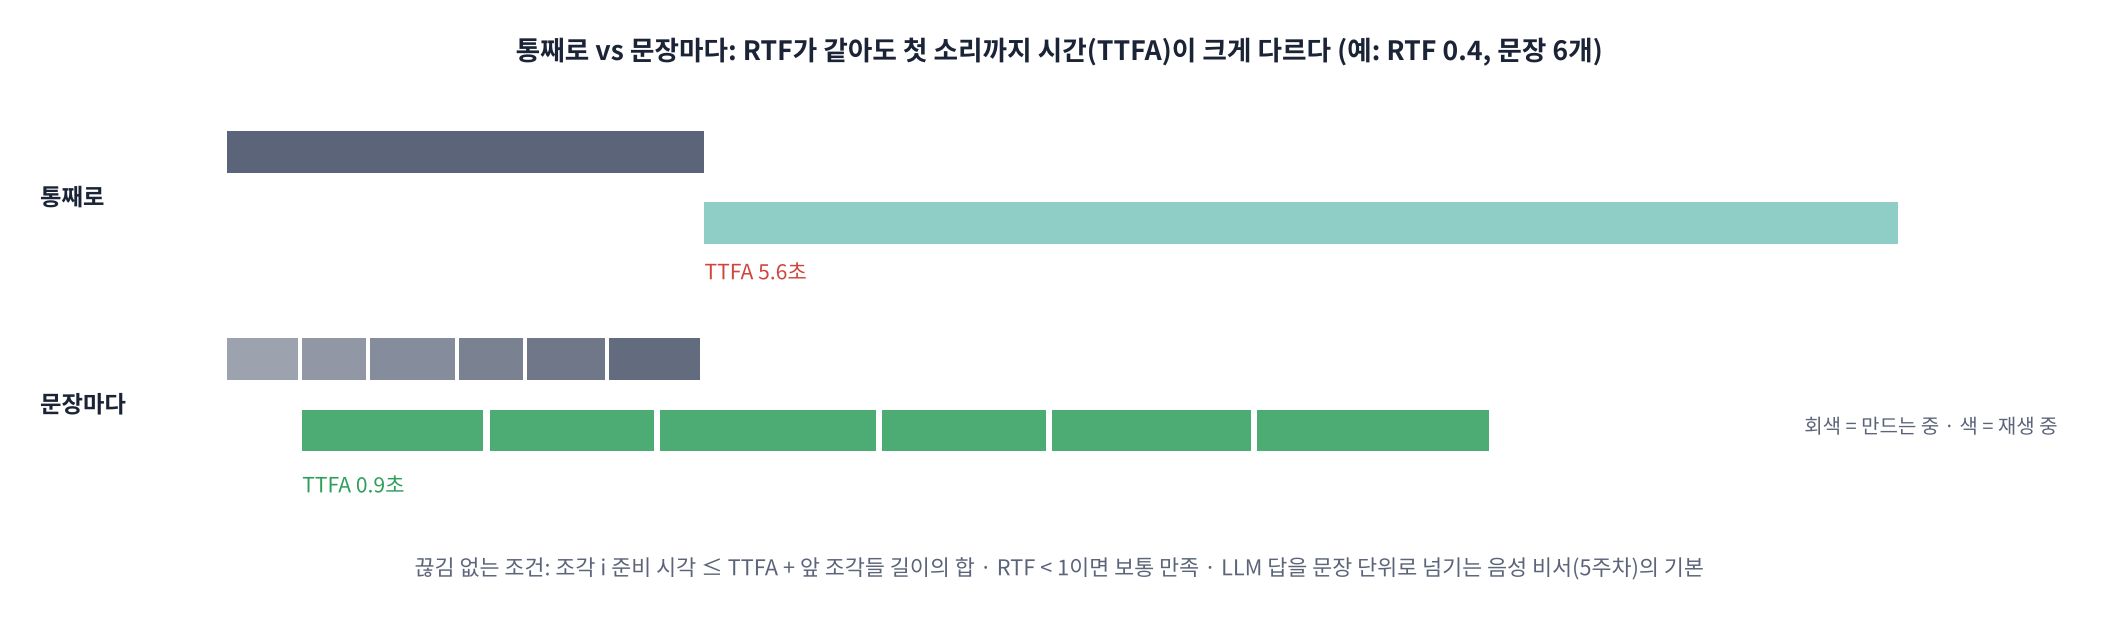

> 📐 **핵심 식 하나: 끊김 없는 재생 조건** — 조각 i가 준비된 시각 ≤ TTFA + (앞 조각들 소리 길이의 합). RTF < 1이고 첫 조각이 짧을수록 쉽게 만족합니다.

> 🎬 **애니메이션 D17-6:** [스트리밍 시뮬레이터](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#stream) — 조각 수 · RTF를 바꾸며 첫 소리 시간과 끊김 보기

> 🎬 **애니메이션 D17-9:** [실시간 예산 계산기](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#cpu) — ASR · LLM 시간과 첫 조각 길이로 '질문 끝 → 첫 소리' 계산

> ## 🎤 강사 스크립트 · Part 5 CPU 실시간  ⏱️ 8분
>
> 🎯 **실시간 = RTF < 1 그리고 첫 소리가 빨리. 문장 단위 스트리밍.**
>
> 🖥️ [D17-6 스트리밍 시뮬레이터](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#stream): 조각 1개 vs 6개, RTF 1.2로 올리면 끊김(빨강).
>
> ✅ 속도 표 예: CPU 1스레드 RTF가 2스레드보다 큼, GPU(T4)는 RTF 0.02 ~ 0.05 근처. 숫자는 런타임마다 다름.

In [ ]:
PARA = ("Kokoro is a lightweight text to speech model. It has only eighty two million parameters. "
        "Because it is small, it can run on an ordinary laptop processor. "
        "The voice is chosen with a small style vector. Long text is split into sentences before synthesis. "
        "This lets a voice assistant start talking before the whole answer is ready.")

def measure(pipeline, text, voice="af_heart", **kw):
    t0 = time.time(); n = 0; total = 0
    for r in pipeline(text, voice=voice, **kw):
        n += 1; total += len(r.audio)
    el = time.time() - t0
    return dict(조각=n, 소리_초=round(total / SR_K, 2), 생성_초=round(el, 2), RTF=round(el / (total / SR_K), 3))

measure(pipe, "warm up")                               # 첫 실행의 준비 시간 빼기
rows = []
for th in sorted({1, N_CPU}):
    torch.set_num_threads(th)
    rows.append(dict(장치=f"CPU {th}스레드", **measure(pipe, PARA)))
torch.set_num_threads(N_CPU)
if GPU:
    kgpu = KModel(repo_id=REPO).to("cuda").eval()
    pipe_gpu = KPipeline(lang_code="a", repo_id=REPO, model=kgpu)
    measure(pipe_gpu, "warm up")
    rows.append(dict(장치="GPU", **measure(pipe_gpu, PARA)))
SPEED = pd.DataFrame(rows)
display(SPEED)

### 🧩 빈칸 실습 7: 문장마다 흘려보내기
`split_pattern`은 텍스트를 **조각으로 나누는 정규식**입니다. `None`이면 (음소 510개를 넘지 않는 한) 통째로 한 번에 만듭니다. 문장마다 줄을 바꾼 글을 **줄바꿈 기준**으로 나누는 정규식을 넣으세요(기본값과 같음). 각 조각이 나온 시각을 기록해 TTFA와 끊김 여부를 봅니다.

In [ ]:
# 🧩 빈칸 실습 7
LINES = re.sub(r"(?<=\.) ", "\n", PARA)                 # 문장마다 줄바꿈

def stream_log(split):
    t0 = time.time(); log = []
    for r in pipe(LINES, voice="af_heart", split_pattern=split):
        log.append(dict(준비_시각=time.time() - t0, 길이=len(r.audio) / SR_K, 글자=r.graphemes[:40]))
    df = pd.DataFrame(log)
    df["재생_시작"] = df["준비_시각"].iloc[0] + df["길이"].cumsum().shift(fill_value=0)   # 앞 조각이 끝나는 시각
    df["끊김"] = df["준비_시각"] > df["재생_시작"] + 1e-9
    return df

whole = stream_log(None)
stream = stream_log(____)                                                                 # 빈칸 7
TTFA_W, TTFA_S = whole["준비_시각"].iloc[0], stream["준비_시각"].iloc[0]
print(f"통째로: 조각 {len(whole)}개 · 첫 소리까지 {TTFA_W:.2f}초")
print(f"문장마다: 조각 {len(stream)}개 · 첫 소리까지 {TTFA_S:.2f}초 · 끊김 {int(stream['끊김'].sum())}번")
display(stream.round(2))

fig, ax = plt.subplots(figsize=(10, 2.2))
for i, r in stream.iterrows():
    ax.barh(1, r.길이, left=r.재생_시작, color="tab:green" if not r.끊김 else "tab:red", edgecolor="white")
    ax.plot([r.준비_시각] * 2, [0.55, 0.75], color="k")
ax.barh(0, whole["길이"].sum(), left=TTFA_W, color="tab:gray")
ax.set_yticks([0, 1]); ax.set_yticklabels(["whole", "stream"]); ax.set_xlabel("seconds (black tick = chunk ready)")
plt.tight_layout(); plt.show()
check(len(stream) == LINES.count("\n") + 1 and TTFA_S < TTFA_W, hint='빈칸 7 = r"\\n+"')

> ## 🎤 강사 스크립트 · 빈칸 실습 7  ⏱️ 10분
>
> 🆘 "줄바꿈 하나 이상을 뜻하는 정규식(raw 문자열)" → `r"\n+"`
>
> ✅ 예상 출력: `통째로: 조각 1개 · 첫 소리까지 3 ~ 6초`, `문장마다: 조각 6개 · 첫 소리까지 0.5 ~ 1초 · 끊김 0번`(CPU RTF < 1일 때), 타임라인 그림, `✅`.
>
> ❓ 5주차 연결: "LLM 답을 언제 TTS에 넘기나?" → 문장 끝마다.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
stream = stream_log(r"\n+")
```

**해설**: 문장마다 나누면 첫 조각은 짧은 한 문장이라 금방 나오고(TTFA ↓), 그 문장을 재생하는 동안 다음 문장을 만듭니다. 표의 '끊김'이 모두 False면 끊김 없이 이어서 들립니다. RTF가 1에 가깝거나 문장 길이가 들쭉날쭉하면 짧은 문장 뒤 긴 문장에서 끊길 수 있습니다. 이때는 ① 첫 조각을 더 짧게(쉼표 단위) ② 버퍼를 조금 쌓고 시작 ③ 더 빠른 장치를 씁니다. 이것이 5 · 6주차 **음성 비서 지연(latency) 설계**의 기본입니다. 참고로 영어 이외 언어는 Kokoro가 문장 부호로 약 400자씩 나눕니다.

</details>

**❓ 생각해 보기**: LLM이 답을 한 단어씩 만들어 내는 음성 비서(5주차)에서는 TTS에 텍스트를 언제 넘겨야 할까요?

<details>
<summary>답 보기</summary>

LLM 답이 **다 끝나기를 기다리지 않고**, 문장 끝(. ? !)이나 쉼표가 나올 때마다 그 조각을 TTS에 넘깁니다. 오늘의 스트리밍과 같은 원리로, 사용자는 LLM이 아직 뒷부분을 생각하는 동안 앞부분을 듣습니다. 너무 잘게(단어마다) 넘기면 억양이 끊기고, 너무 크게 넘기면 기다림이 깁니다. 그래서 **문장 · 구 단위**가 보통의 타협점입니다(D21 Latency Budget).

</details>

## Part 6. 한국어는? 음소를 직접 넣어 보기

> 💬 **쉽게 말하면**: Kokoro에는 한국어 목소리 · 한국어 G2P가 없습니다. 하지만 `KModel`은 **음소만 받으므로**, espeak-ng로 한국어를 **IPA 음소**로 바꿔 넣으면 다른 언어 목소리로 '한국어 비슷한' 소리를 낼 수 있습니다. 결과는 **외국인 억양**에 가깝습니다. 모델이 한국어 소리를 배운 적이 없기 때문입니다. D16의 정규화 · G2P를 앞에 붙이면 얼마나 나아지는지, 한국어로 학습한 VITS와 **ASR 역검증**으로 비교합니다.

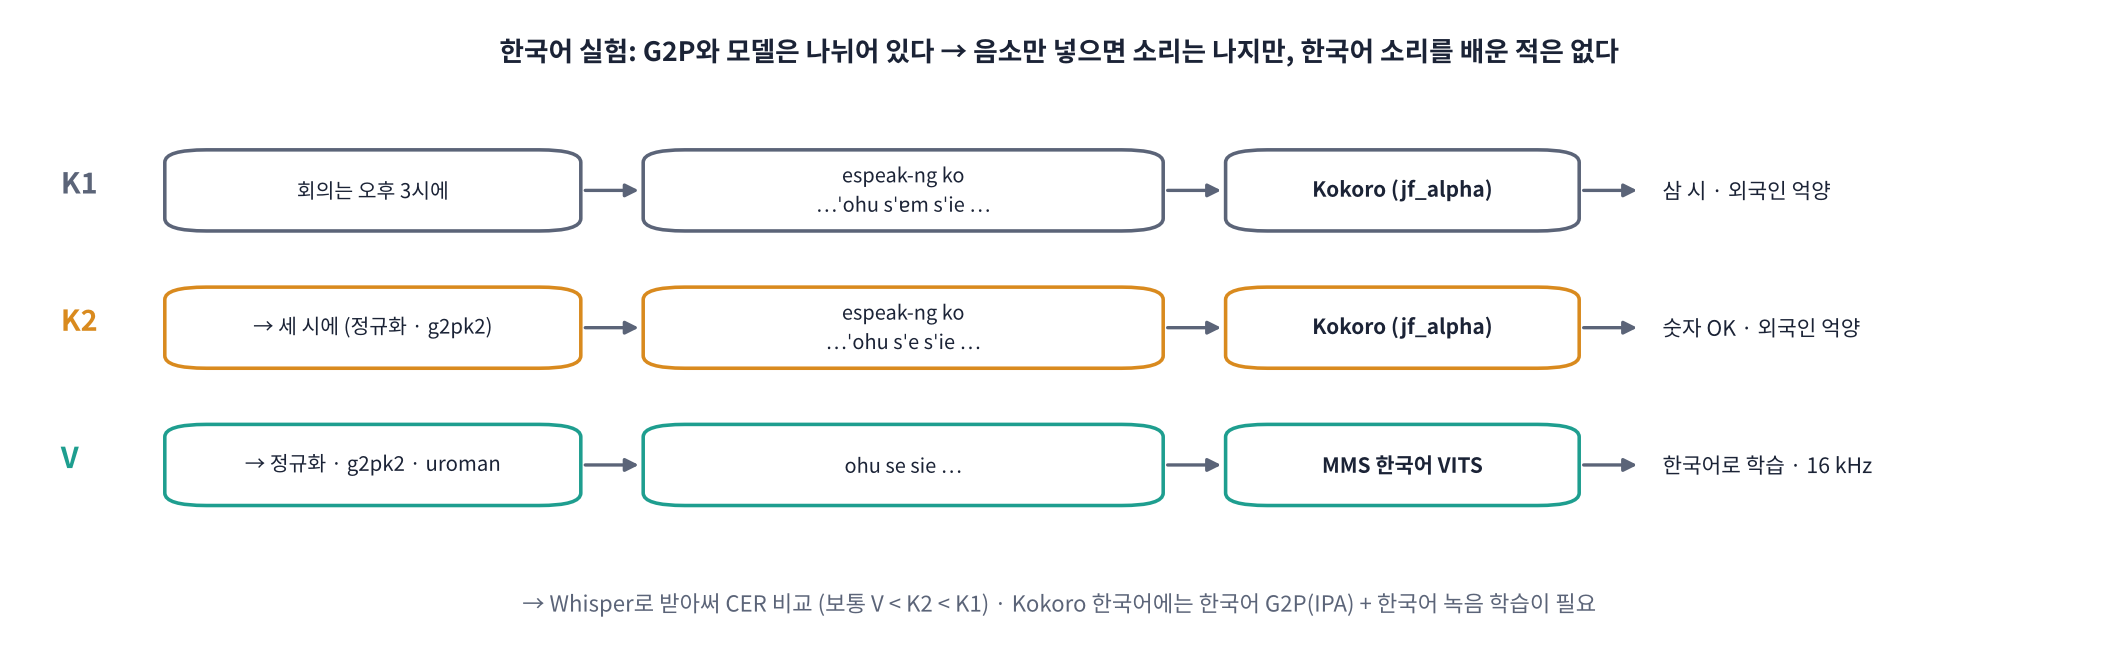

| 조건 | 입력 처리 | 모델 |
|---|---|---|
| K1 | 원문 → espeak-ng(ko) → IPA | Kokoro + 다른 언어 목소리 |
| K2 | 원문 → **normalize_ko → g2pk2** (D16) → espeak-ng(ko) → IPA | Kokoro + 다른 언어 목소리 |
| V | 원문 → normalize_ko → g2pk2 → uroman (D16의 C) | **MMS-TTS 한국어 VITS** (한국어로 학습) |

> 🎬 **애니메이션 D17-7:** [한국어 음소 실험](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#korean) — 원문 · G2P 처리 후 espeak 음소를 비교하고 버려지는 기호 보기

> ## 🎤 강사 스크립트 · Part 6 한국어 실험  ⏱️ 15분
>
> 🎯 **G2P와 모델이 나뉘어 있어 음소만 넣으면 소리는 난다. 하지만 한국어를 배운 적 없는 모델은 외국인 억양.**
>
> 🖥️ [D17-7 한국어 음소 실험](https://imguru-mooc.github.io/AI_Voice/day17/animation.html#korean): espeak-ng 원문 vs D16 처리 후 음소 비교.
>
> 🗣️ "어제 만든 정규화와 g2pk2를 그대로 가져옵니다. 코드가 쌓여 가는 것을 느껴 보세요."

In [ ]:
# D16에서 가져온 도구: 한국어 정규화 (빈칸 없음, 설명은 D16 Part 2)
DIGITS = "영일이삼사오육칠팔구"
def sino(n):
    if n == 0: return "영"
    out = ""
    for big in ["", "만", "억", "조"]:
        chunk, n = n % 10000, n // 10000; s = ""
        for i, unit in enumerate(["", "십", "백", "천"]):
            d, chunk = chunk % 10, chunk // 10
            if d: s = ("" if d == 1 and i > 0 else DIGITS[d]) + unit + s
        if s: out = ("" if s == "일" and big == "만" else s) + big + out
        if n == 0: break
    return out
ONES = ["", "한", "두", "세", "네", "다섯", "여섯", "일곱", "여덟", "아홉"]
TENS = ["", "열", "스물", "서른", "마흔", "쉰", "예순", "일흔", "여든", "아흔"]
def native(n): return sino(n) if not 0 < n < 100 else ("스무" if n == 20 else TENS[n // 10] + ONES[n % 10])
NATIVE_COUNTERS = ["시간", "개", "명", "살", "마리", "권", "잔", "병", "장", "달", "시"]
def read_number(s):
    s = s.replace(",", "")
    if "." in s:
        a, b = s.split(".", 1); return sino(int(a)) + "점" + "".join(DIGITS[int(c)] for c in b)
    return sino(int(s))
def normalize_ko(t):
    t = re.sub(r"(\d+)\s*(" + "|".join(NATIVE_COUNTERS) + ")", lambda m: native(int(m.group(1))) + " " + m.group(2), t)
    t = re.sub(r"(\d[\d,]*(?:\.\d+)?)\s*%", lambda m: read_number(m.group(1)) + " 퍼센트", t)
    t = re.sub(r"\d[\d,]*(?:\.\d+)?", lambda m: read_number(m.group(0)), t)
    return re.sub(r"\s+", " ", t).strip()

from g2pk2 import G2p
g2p = G2p()
from misaki import espeak
ko_ipa = espeak.EspeakG2P(language="ko")                 # espeak-ng의 한국어 음소 규칙

KO_SENTS = ["같이 밥을 먹으러 갈까요", "국물이 정말 맛있네요", "회의는 오후 3시에 시작합니다",
            "가격은 12,500원입니다", "안녕하세요 반갑습니다", "학교까지 걸어갔습니다"]
print(normalize_ko("회의는 오후 3시에 시작합니다"), "→", g2p(normalize_ko("회의는 오후 3시에 시작합니다")))

### 🧩 빈칸 실습 8 · 9: 음소를 직접 넣어 합성하기
- 빈칸 9: `KModel`이 아는 음소 기호 사전(기호 → id)의 **속성 이름**. 사전에 없는 기호는 모델이 조용히 버리므로 미리 확인합니다.
- 빈칸 8: 글자가 아니라 **음소 문자열을 바로** 넣는 파이프라인 메서드 이름 (`generate_from_…`)

In [ ]:
# 🧩 빈칸 실습 8 · 9
VOCAB = set(kmodel.____)                                                                  # 빈칸 9
KO_VOICE = "jf_alpha"                                    # ✏️ 바꿔 보기: "af_heart", "ff_siwis" …

def ko_phonemes(text, mode):
    src = text if mode == "K1" else g2p(normalize_ko(text))
    ps = ko_ipa(src)[0]
    return ps, sorted(set(ps) - VOCAB - {" "})

def kokoro_ko(ps):
    torch.manual_seed(0)
    return torch.cat([r.audio for r in pipe.____(ps, voice=KO_VOICE)])                    # 빈칸 8

for s in KO_SENTS[:4]:
    for mode in ["K1", "K2"]:
        ps, dropped = ko_phonemes(s, mode)
        print(f"{mode} {s:16s} → {ps:50s} 버려지는 기호: {''.join(dropped) or '없음'}")
ps, _ = ko_phonemes(KO_SENTS[0], "K2")
y_ko = kokoro_ko(ps)
play(y_ko, label=f"Kokoro {KO_VOICE} · K2 · {KO_SENTS[0]}")
check(len(VOCAB) > 50 and "ə" in VOCAB and y_ko.numel() > 0, hint="빈칸 8 = generate_from_tokens, 빈칸 9 = vocab")

> ## 🎤 강사 스크립트 · 빈칸 실습 8 · 9 · ASR 역검증  ⏱️ 15분
>
> 🆘 빈칸 9: "KModel이 가진 기호 → id 사전 속성" → `vocab`
> 🆘 빈칸 8: "generate_from_…, 음소를 '토큰'으로 바로" → `generate_from_tokens`
>
> ✅ 예상 출력: K1 · K2 음소 줄(K1 '3시' → sˈɐm sˈie, K2 → sˈe sˈie), 버려지는 기호(대개 없음 또는 1 ~ 2개), 🎧 Kokoro 한국어(외국인 억양), `✅`.
>
> 다음 셀(3 ~ 5분): 평균 CER 표(보통 V < K2 < K1), 문장별 표, 🎧 세 조건.
>
> 🎧 스피커로 K1 → K2 → V 순서. ❓ "Kokoro로 한국어 서비스를 하려면?" → 한국어 G2P(IPA) + 한국어 녹음 학습(❓ 생각해 보기).
>
> ⚠️ `KO_VOICE`를 af_heart · ff_siwis 등으로 바꿔 보게 하면 재미있어함. 정답은 없음.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
VOCAB = set(kmodel.vocab)
return torch.cat([r.audio for r in pipe.generate_from_tokens(ps, voice=KO_VOICE)])
```

**해설**: `generate_from_tokens`는 G2P를 건너뛰고 음소 문자열(510자 이하)을 바로 모델에 넣습니다. espeak-ng 한국어 규칙은 **연음 · 숫자 읽기가 약해서**(밥을 → pɐpˈɯɫ, 3시 → 삼 시) D16의 정규화 · g2pk2를 먼저 하면 음소가 실제 발음에 가까워집니다(K2: 바블 → pɐbˈɯɫ, 세 시). 'q'처럼 espeak가 쓰는 기호 중 일부는 Kokoro가 영어 · 일본어를 배울 때 거의 못 본 기호라 이상하게 나거나 버려집니다. 목소리를 일본어(jf_alpha)로 고른 이유는 일본어 모음 체계가 한국어와 비교적 가깝기 때문인데, 정답은 없으니 바꿔 들어 보세요.

</details>

In [ ]:
# 세 조건을 Whisper로 받아써 비교 (D16 Part 7과 같은 방법)
from transformers import WhisperProcessor, WhisperForConditionalGeneration, VitsModel, AutoTokenizer, set_seed
import uroman as ur

DEVICE = "cuda" if GPU else "cpu"
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME, language="korean", task="transcribe")
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()
vits_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
vits = VitsModel.from_pretrained("facebook/mms-tts-kor").eval()
U = ur.Uroman()

def vits_ko(text):
    set_seed(0)
    with torch.no_grad():
        return vits(**vits_tok(U.romanize_string(g2p(normalize_ko(text))), return_tensors="pt")).waveform[0]

def transcribe(wavs, sr):
    xs = [librosa.resample(np.asarray(w, dtype=np.float32), orig_sr=sr, target_sr=16000) for w in wavs]
    feats = asr_proc.feature_extractor(xs, sampling_rate=16000, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=128)
    return [t.strip() for t in asr_proc.batch_decode(ids, skip_special_tokens=True)]

def for_cer(s):
    return re.sub(r"[^\w]", "", normalize_ko(s))

WAVS = {"K1": [kokoro_ko(ko_phonemes(s, "K1")[0]).numpy() for s in KO_SENTS],
        "K2": [kokoro_ko(ko_phonemes(s, "K2")[0]).numpy() for s in KO_SENTS],
        "V":  [vits_ko(s).numpy() for s in KO_SENTS]}
SRS = {"K1": SR_K, "K2": SR_K, "V": vits.config.sampling_rate}
rows = []
for cond, wavs in WAVS.items():
    for s, h in zip(KO_SENTS, transcribe(wavs, SRS[cond])):
        rows.append(dict(조건=cond, 원문=s, 받아쓰기=h, CER=100 * jiwer.cer(for_cer(s), for_cer(h) or "∅")))
KO_BACK = pd.DataFrame(rows)
display(KO_BACK.groupby("조건")["CER"].mean().round(1).to_frame("평균 CER(%)"))
display(KO_BACK.pivot(index="원문", columns="조건", values="CER").round(0))
for cond in WAVS:
    r = KO_BACK[(KO_BACK.조건 == cond) & (KO_BACK.원문 == KO_SENTS[2])].iloc[0]
    play(WAVS[cond][2], SRS[cond], label=f"{cond} → Whisper: {r.받아쓰기} (CER {r.CER:.0f}%)")

**결과 읽기 · 들어 보기** (숫자는 실행마다 다릅니다)
- 보통 **V(한국어로 학습한 VITS) < K2 < K1** 순서로 CER이 낮습니다. Kokoro는 음소를 넣어 줘도 **한국어 소리(받침 · 된소리 · 억양)를 배운 적이 없어** 외국인 억양처럼 들립니다.
- K1 → K2 차이는 D16에서 본 **정규화 · G2P의 효과**입니다. 특히 '3시', '12,500원' 문장에서 큽니다.
- 결론: Kokoro로 한국어 서비스를 하려면 **한국어 녹음으로 학습(fine-tuning)** 해야 합니다. 그 전까지 한국어 TTS는 한국어로 학습한 모델(오늘의 MMS-TTS, D18에서 찾아볼 한국어 지원 표현형 모델)을 씁니다.

**❓ 생각해 보기**: Kokoro 구조 그대로 한국어를 학습시키려면 무엇이 필요할까요?

<details>
<summary>답 보기</summary>

① **한국어 G2P → IPA** 변환기(g2pk2 결과를 IPA로 바꾸는 규칙, misaki에 넣을 한국어 모듈) ② **한국어 녹음 + 정확한 대본** 수십 ~ 수백 시간(D11의 데이터 · 품질 기준), 목소리마다 동의 ③ 한국어에만 있는 소리(된소리 · 받침)를 나타낼 **음소 기호**가 모델 사전에 있어야 함 ④ 학습 GPU 수백 시간. Kokoro 개발자도 '언어 지원이 약한 이유는 G2P와 데이터'라고 밝히고 있습니다. 데이터 · G2P가 모델 크기보다 중요하다는 것, 3주차 ASR Fine-tuning과 같은 교훈입니다.

</details>

---
### 📝 4교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day17/worksheet.html)** — RTF와 TTFA의 차이, 스레드 수, 문장 단위 스트리밍, 끊김 없는 재생 조건, split_pattern, LLM 스트리밍 연결, generate_from_tokens, espeak-ng 한국어 음소, 버려지는 기호, 외국인 억양의 이유, ASR 역검증 결과 읽기
>
> 10문항을 풀고 **채점하기**를 누르세요.

> ## 🎤 강사 스크립트 · 4교시 워크시트 · 제출  ⏱️ 5분
>
> 🖥️ [worksheet.html 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day17/worksheet.html) → 채점 → 제출 → 📋 캡처 → 노션. **Part 5 속도 표 · Part 6 CER 표**도 함께.
>
> 자주 틀리는 문항: **RTF와 TTFA의 차이**, **끊김 없는 조건**.

## Part 7. 정리 & 과제

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| Kokoro 구조 | StyleTTS 2 + iSTFTNet, 82M, Apache 2.0, 24 kHz | `KModel` |
| 파이프라인 | 언어별 G2P(misaki) + voice 관리, 모델은 공유 | `KPipeline(lang_code="a", model=kmodel)` |
| 음소 · 강세 | IPA + A · I · O · W · Y · T 약속 기호, ˈ · ˌ 강세 | `r.phonemes` |
| 길이 · 자막 | 프레임 600 샘플(25 ms), 단어 시작 · 끝 시간 | `r.pred_dur`, `t.start_ts` |
| voice pack | (510, 1, 256), 음소 수로 줄 선택, 음색 128 + 운율 128 | `pack[len(ps) - 1]` |
| 목소리 섞기 | 선형 보간 · 쉼표 평균 | `(1 - w) * pa + w * pb` |
| 실시간 | RTF < 1 + 짧은 TTFA, 문장 단위 스트리밍 | `split_pattern=r"\n+"` |
| 음소 직접 입력 | G2P를 건너뛰고 모델에 IPA | `pipe.generate_from_tokens(ps, voice)` |

### 📝 과제
1. **내 서비스 목소리 만들기**: 영어 목소리 3개를 골라 비율을 바꿔 섞고, 같은 문장 5개로 길이 · 음높이 표를 만든 뒤 '안내 방송용'으로 가장 좋은 조합과 이유를 쓰세요.
2. **자막 파일**: 영어 문단 하나를 합성하고 `start_ts` · `end_ts`로 `.srt` 파일을 만들어, 동영상 플레이어에서 소리와 맞는지 확인하세요.
3. **실시간 예산**: Colab CPU에서 RTF와 TTFA를 바탕으로 '질문 끝 → 첫 소리'까지 0.5초 안에 들어오려면 첫 조각을 몇 단어로 해야 하는지 계산하세요.

### ✅ 개념 워크시트 제출
4교시 탭까지 모두 채점했다면 오늘 내용을 정리해 제출합니다.

> 📝 **[D17 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day17/worksheet.html)** — 4교시 × 10문항 (객관식 5 · OX 2 · 선잇기 1 · 순서 맞추기 1 · 모두 고르기 1)

**제출 방법 (노션)**
1. 4개 교시 탭을 모두 채점합니다.
2. **제출** 버튼을 눌러 오답 정리를 엽니다.
3. **📋 캡처 (노션용 복사)**를 누른 뒤, 노션 제출 페이지에서 `Ctrl + V`로 붙여 넣습니다. **Part 5 속도 표 · Part 6 평균 CER 표**도 함께 붙이세요.

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day17/animation.html) — D17-1 ~ D17-9

### 다음 시간 (D18 · 표현형 TTS)
**감정 · 억양 제어**: Chatterbox로 감정 세기를 조절하고, F5-TTS · CosyVoice 같은 오픈소스 모델을 비교합니다. 오늘 본 '음색과 운율을 나누는 생각'이 어떻게 발전했는지, 그리고 **한국어를 지원하는 표현형 모델**을 찾아 같은 ASR 역검증으로 평가합니다.

> ## 🎤 강사 스크립트 · Part 7 정리  ⏱️ 3분
>
> 🎯 **오늘 한 줄: 작은 모델 + 음소 입력 + 스타일 벡터 = CPU 실시간 · 여러 목소리. 단, 언어는 데이터와 G2P가 정한다.**
>
> ➡️ "내일은 감정과 억양을 조절하는 표현형 TTS입니다. 오늘 '음색 / 운율'을 나눠 본 생각이 어떻게 발전했는지 보고, 한국어를 지원하는 모델을 찾아 같은 역검증으로 평가합니다."